# First analysis to load AV_Dome data from RDSS and get Learning curves 

In [61]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
# import seaborn as sns
import os
from pathlib import Path
import xarray as xr
from modules.loading_functions import load_sessions



In [62]:
cohordID = "main"
# cohordID = "main_4Hz"
# cohordID = "main_closedLoop"

if cohordID == "main":
    # This assumes that you mounted the AV_Dome prject folder as a mapped network drive "Z:". If you mounted it to a different location, please change the path below.
    root_folder = Path(r"Z:\AV_Dome")

    # list all available subjects:
    dirs = [p for p in root_folder.iterdir() if p.is_dir()]

    all_subjects = []
    for i in dirs:
        subject = i.name.split("sub-")[-1]
        all_subjects.append(subject)
    #
    all_subjects = np.array(all_subjects)

    mice2exclude = ["AM008", "AM009"]

    all_subjects = all_subjects[(all_subjects != "AM008") & (all_subjects != "AM009")]

    # ## OVERWRITE FOR NOW!!!
    # all_subjects = ["GN011", "GN012", "GN013", "GN014", "GN015"]
    # all_subjects = ["GN013", "GN014", "GN015", "AM009", "AM018", "AM020"]
    # all_subjects = ["GN013", "GN014", "GN015"]
    # all_subjects = ["AM009", "AM018", "AM020"]
    # all_subjects = ["Gary"]

    # These mice were moved to 4Hz for testing
    all_subjects = all_subjects[(all_subjects != "GN011") & (all_subjects != "GN012")]

    # Initial testing mice
    all_subjects = all_subjects[(all_subjects != "GN002") & (all_subjects != "GN008")]

    df = load_sessions(root_folder, all_subjects)
elif cohordID == "main_4Hz":
    # This assumes that you mounted the AV_Dome prject folder as a mapped network drive "Z:". If you mounted it to a different location, please change the path below.
    root_folder = Path(r"Z:\AV_Dome_4Hz_movingStim")

    # list all available subjects:
    dirs = [p for p in root_folder.iterdir() if p.is_dir()]

    all_subjects = []
    for i in dirs:
        subject = i.name.split("sub-")[-1]
        all_subjects.append(subject)
    #

    df = load_sessions(root_folder, all_subjects)
elif cohordID == "main_closedLoop":
    # This assumes that you mounted the AV_Dome prject folder as a mapped network drive "Z:". If you mounted it to a different location, please change the path below.
    root_folder = Path(r"Z:\AV_Dome_ClosedLoop")

    # list all available subjects:
    dirs = [p for p in root_folder.iterdir() if p.is_dir()]

    all_subjects = []
    for i in dirs:
        subject = i.name.split("sub-")[-1]
        all_subjects.append(subject)
    #

    # # ## OVERWRITE FOR NOW!!!
    # all_subjects = ["GN011", "GN012", "GN013", "GN014", "GN015"]

    df = load_sessions(root_folder, all_subjects)
#


In [63]:
def compute_performance(dataFrame):
    # Not sure this is necesarry, but want to make sure I'm not manipulating the source!
    df = dataFrame.copy()
    
    # Current results output doesn't include both_spouts! Need to investigate and add this filter in the future, but for now, skip that mask.
    trialMask = ((df.correctResponse == "Correct") | (df.correctResponse == "Incorrect")) & \
                 (df.BothSpouts == "True") & \
                 (df.autoReward == "False") & \
                 (df.IsRepeat == "False") & \
                 ((df.RepeatCount).astype(int) == 0)  # Those two should be redundant but just in case
        
    trialCnt = np.sum(trialMask)
    df = df.loc[trialMask]

    rightResponses = (df.response == "Right").astype(np.float32)
    p_right = np.mean(rightResponses)
    correctResponses = (df.correctResponse == "Correct").astype(np.float32)
    performance = np.mean(correctResponses)
    return performance, trialCnt, p_right
#

def compute_bias(dataFrame):
    # Not sure this is necesarry, but want to make sure I'm not manipulating the source!
    df = dataFrame.copy()
    
    # Current results output doesn't include both_spouts! Need to investigate and add this filter in the future, but for now, skip that mask.
    trialMask = (df.correctResponse == "Incorrect") & \
                (df.BothSpouts == "True") & \
                (df.autoReward == "False") & \
                (df.IsRepeat == "False") & \
                ((df.RepeatCount).astype(int) == 0)  # Those two should be redundant but just in case
        
    trialCnt = np.sum(trialMask)
    df = df.loc[trialMask]

    rightResponses = (df.response == "Right").astype(np.float32)
    rightBias = np.mean(rightResponses)
    return rightBias

def compute_performance_by_side(dataFrame):
    # Not sure this is necesarry, but want to make sure I'm not manipulating the source!
    df = dataFrame.copy()
    
    # Current results output doesn't include both_spouts! Need to investigate and add this filter in the future, but for now, skip that mask.
    trialMask = ((df.correctResponse == "Correct") | (df.correctResponse == "Incorrect")) & \
                 (df.BothSpouts == "True") & \
                 (df.autoReward == "False") & \
                 (df.IsRepeat == "False") & \
                 ((df.RepeatCount).astype(int) == 0)  # Those two should be redundant but just in case
        
    trialCnt = np.sum(trialMask)
    df = df.loc[trialMask]

    df_left = df[df.target_side == "Left"]
    df_right = df[df.target_side == "Right"]

    pCorrectLeft = (df_left.correctResponse == "Correct").astype(np.float32).mean()
    pCorrectRight = (df_right.correctResponse == "Correct").astype(np.float32).mean()

    nTrialsLeft = len(df_left.correctResponse)
    nTrialsRight = len(df_right.correctResponse)

    return pCorrectRight, pCorrectLeft, nTrialsLeft, nTrialsRight
#

def compute_responded_by_side(dataFrame):
    # Not sure this is necesarry, but want to make sure I'm not manipulating the source!
    df = dataFrame.copy()
    
    # Current results output doesn't include both_spouts! Need to investigate and add this filter in the future, but for now, skip that mask.
    trialMask = (df.BothSpouts == "True") & \
                (df.autoReward == "False") & \
                (df.IsRepeat == "False") & \
                ((df.RepeatCount).astype(int) == 0)  # Those two should be redundant but just in case
        
    df = df.loc[trialMask]

    df_left = df[df.target_side == "Left"]
    df_right = df[df.target_side == "Right"]

    pRespondedLeft = 1 - (df_left.correctResponse == "NoResponse").astype(np.float32).mean()
    pRespondedRight = 1 - (df_right.correctResponse == "NoResponse").astype(np.float32).mean()

    return pRespondedRight, pRespondedLeft
#


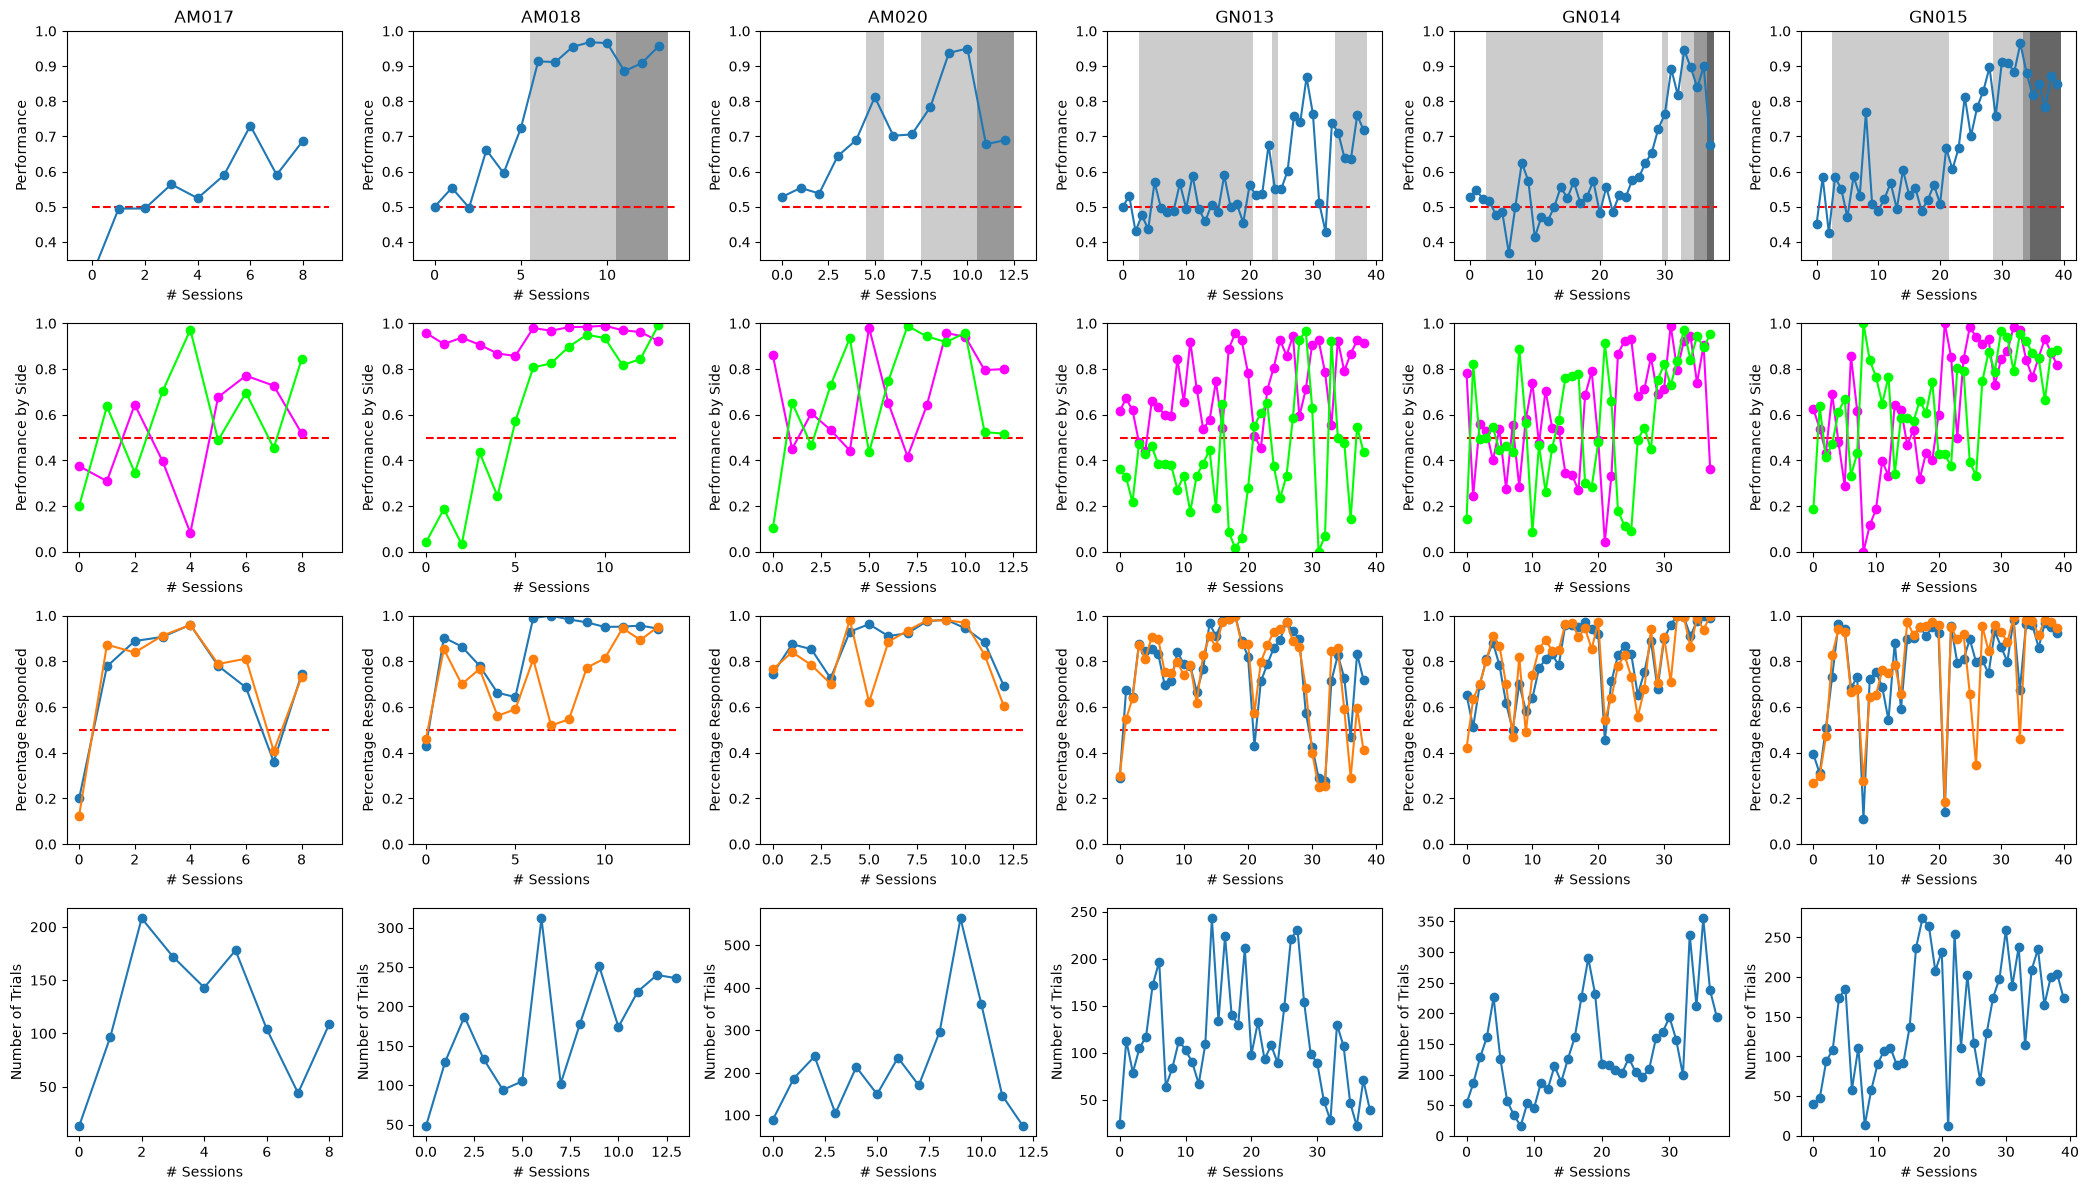

In [64]:
# df.
all_mice = np.sort(np.unique(df.subject))
all_mice = all_mice[(all_mice != "Dummy") & (all_mice != "Gary")]

fig, ax = plt.subplots(4, np.max([2, len(all_mice)]), figsize=[len(all_mice) * 3.5, 12])

# session_ids = list()
performance = list()
bias = list()
percentage_responded = list()
nTrials = list()
trainingStage = list()
# trialCnt = list()
for subject_id, subject in enumerate(all_mice):
    session_ids = df[df.subject == subject].session_id.unique()
    performance.append(list())
    bias.append(list())
    percentage_responded.append(list())
    nTrials.append(list())
    trainingStage.append(list())
    # trialCnt.append(list())
    for session_id in np.sort(session_ids):
        try:
            session_df = df[(df.subject == subject) & (df.session_id == session_id)]

            perf, trialCnt, p_right = compute_performance(session_df)


            # rightBias = compute_bias(session_df)
            pCorrectRight, pCorrectLeft, nTrialsLeft, nTrialsRight = compute_performance_by_side(session_df)

            pRespondedRight, pRespondedLeft = compute_responded_by_side(session_df)

            # if perf > 0.9:
            #     print([perf, nTrialsLeft, nTrialsRight])
            # #
            
            # if trialCnt > 20:
            # if nTrialsLeft > 10 and nTrialsRight > 10:
            if nTrialsLeft > 2 and nTrialsRight > 2:
                performance[subject_id].append(perf)
                # bias[subject_id].append(rightBias)
                bias[subject_id].append([pCorrectRight, pCorrectLeft])
                percentage_responded[subject_id].append([pRespondedRight, pRespondedLeft])
                nTrials[subject_id].append(nTrialsLeft + nTrialsRight)
                trainingStage[subject_id].append(session_df.trainingStage.iloc[0])
            #
        except Exception as e:
            pass
        #
    #

    try:
        temp_bias = np.array(bias[subject_id])
        
        c_ax = ax[0, subject_id]
        for i in range(len(trainingStage[subject_id])):
                trainingStage[subject_id][i]
                c_ax.add_patch(Rectangle([i-0.5, 0], 1, 1, facecolor=np.array([1, 1, 1]) - 0.2 * trainingStage[subject_id][i]))
        # 

        c_ax.plot([0, len(performance[subject_id])], [0.5, 0.5], "--r")
        c_ax.plot(performance[subject_id], "-o")
        c_ax.set_title(subject)
        c_ax.set_xlabel("# Sessions")
        c_ax.set_ylabel("Performance")
        c_ax.set_ylim([0.35, 1])
        # c_ax.set_ylim([0.35, 0.70])


        c_ax = ax[1, subject_id]
        c_ax.plot([0, len(bias[subject_id])], [0.5, 0.5], "--r")
        # c_ax.plot(bias[subject_id], "-o")
        c_ax.plot(temp_bias[:, 0], "-o", color=[1, 0, 1], label="Right")
        c_ax.plot(temp_bias[:, 1], "-o", color=[0, 1, 0], label="Left")
        c_ax.set_xlabel("# Sessions")
        c_ax.set_ylabel("Performance by Side")
        c_ax.set_ylim([0, 1])
        # c_ax.set_ylim([0.35, 0.70])

        c_ax = ax[2, subject_id]
        c_ax.plot([0, len(percentage_responded[subject_id])], [0.5, 0.5], "--r")
        c_ax.plot(percentage_responded[subject_id], "-o")
        c_ax.set_xlabel("# Sessions")
        c_ax.set_ylabel("Percentage Responded")
        c_ax.set_ylim([0, 1])
        
        c_ax = ax[3, subject_id]
        c_ax.plot(nTrials[subject_id], "-o")
        c_ax.set_xlabel("# Sessions")
        c_ax.set_ylabel("Number of Trials")
    except:
        pass
    #
#

plt.tight_layout()
plt.savefig(f"plots\LearningCurves_{cohordID}.png", dpi=1000)
plt.show()


In [65]:
# np.unique(df[(df.trainingStage == 1) & (df.subject == "GN015")].date)

for date in ["2026-08-21", "2026-08-24", "2026-08-25"]:
    temp_df = df[(df.trainingStage == 1) & (df.subject == "GN015") & (df.date == date)].copy()
    sides = temp_df[temp_df.RepeatCount == "0"].target_side == "Left"

    print("nTrials:" + str(len(sides)) + " | pLeft:" + str(np.mean(sides)) + " | pSideSwitch:" + str(np.abs(np.diff(np.float32(sides))).mean()))
#


nTrials:217 | pLeft:0.46543778801843316 | pSideSwitch:0.49074075
nTrials:246 | pLeft:0.516260162601626 | pSideSwitch:0.49387756
nTrials:74 | pLeft:0.5135135135135135 | pSideSwitch:0.5890411


In [66]:
# # Just to check something:
# audioCondition = 0
# subject_df = df[df.subject == "GN015"]
# temp = np.array((np.array(np.sign(subject_df.audioAzimuth.astype(float))), 
#                  np.array(subject_df.audioAzimuth.astype(float)), 
#                  np.array(subject_df.visualAzimuth.astype(float)), 
#                  np.array(subject_df.visualContrast.astype(float))))
# print(temp[:, -10:])
# np.unique(subject_df.audioAzimuth.astype(float))

np.unique(df.trainingStage)

array([0, 1, 2, 3], dtype=int32)

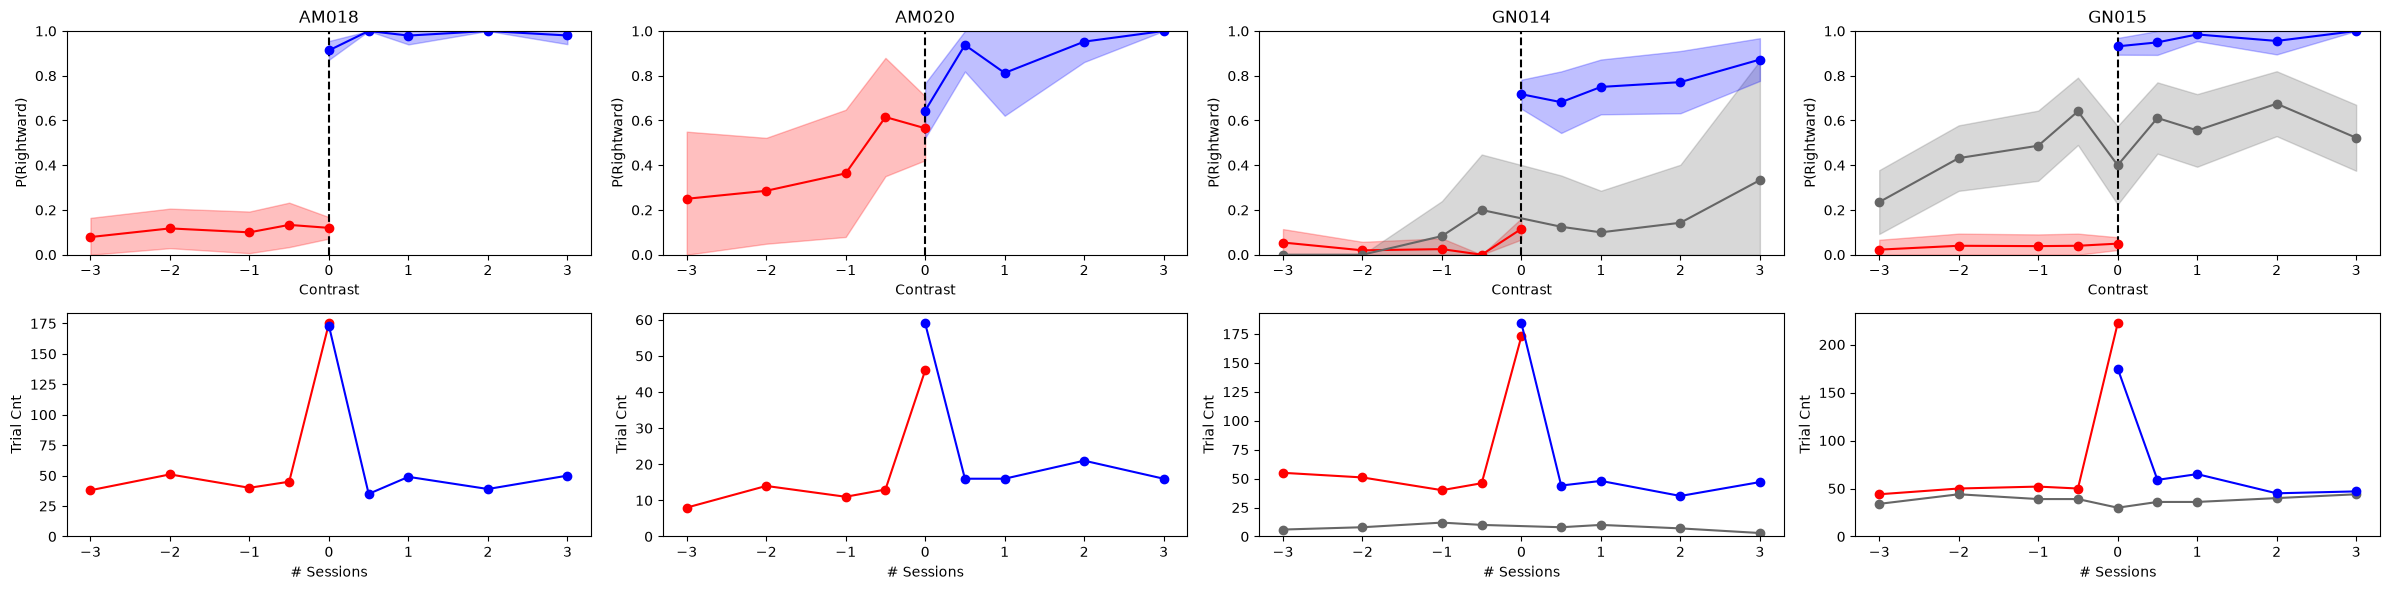

In [67]:
# df.
all_mice = np.sort(np.unique(df.subject))
all_mice = all_mice[(all_mice != "Dummy") & (all_mice != "Gary")]

# Overwrite to only display specific mice:
if cohordID == "main_4Hz":
    all_mice = ["GN011", "GN012"]
else:
    all_mice = ["AM018", "AM020", "GN014", "GN015"]    
#
fig, ax = plt.subplots(2, np.max([2, len(all_mice)]), figsize=[6*len(all_mice), 6])
for subject_id, subject in enumerate(all_mice):
    subject_df = df[df.subject == subject]
    subject_df = subject_df[subject_df.trainingStage > 1]
    
    # make left target negative
    visual_contrasts = np.sort(np.unique(subject_df.visualContrast.astype(float) * (1 - (2 * (subject_df.target_side == "Left").astype(float)))))
    # visual_contrasts = visual_contrasts[(visual_contrasts > -3) & (visual_contrasts < 3)]
    
    # visual_contrasts = [-3, 3]
    visual_contrasts = np.array([-3, -2, -1, -0.5, 0, 0.5, 1, 2, 3], dtype=float)
        
    perf = np.empty([2, len(visual_contrasts), 3])  # The 3 are the 3 type of trials (leftAud, visOnly and rightAud)
    perf[:] = np.nan
    for audioCondition in range(3):  # 0: leftAud, 1: visOnly, 2: rightAud
        for contrast_id, contrast in enumerate(visual_contrasts):
            # perf[0, contrast_id, audioCondition] = contrast

            try:
                target_side = "Left" if contrast < 0 else "Right"
                contrast_df = subject_df[(subject_df.visualContrast.astype(float) == np.abs(contrast)) & (np.sign(subject_df.visualAzimuth.astype(float)) == np.sign(contrast)) & (np.sign(subject_df.audioAzimuth.astype(float)) == audioCondition-1)]
                performance, trialCnt, p_right = compute_performance(contrast_df)
                perf[0, contrast_id, audioCondition] = p_right  # performance
                perf[1, contrast_id, audioCondition] = trialCnt
            except:
                perf[0, contrast_id, audioCondition] = np.nan
                perf[1, contrast_id, audioCondition] = 0
            #
        #
    #

    cl = np.array([[1, 0, 0], [0.4, 0.4, 0.4], [0, 0, 1]])

    c_ax = ax[0, subject_id]
    c_ax.plot([perf[0, :].min(), perf[0, :].max()], [0.5, 0.5], "--k")
    c_ax.plot([0, 0], [0, 1], "--k")
    for audioCondition in range(3):  # 0: leftAud, 1: visOnly, 2: rightAud
        valid = np.isfinite(perf[0, :, audioCondition]) & (perf[1, :, audioCondition] > 0)
        if np.any(valid):
            x = visual_contrasts[valid]
            p = perf[0, valid, audioCondition]
            n = perf[1, valid, audioCondition].astype(float)
            se = np.sqrt((p * (1 - p)) / n)
            ci_low = np.clip(p - 1.96 * se, 0, 1)
            ci_high = np.clip(p + 1.96 * se, 0, 1)
            c_ax.fill_between(x, ci_low, ci_high, color=cl[audioCondition], alpha=0.25)
            c_ax.plot(x, p, "-o", color=cl[audioCondition])
    #
    c_ax.set_title(subject)
    c_ax.set_xlabel("Contrast")
    c_ax.set_ylabel("P(Rightward)")
    c_ax.set_ylim([0, 1])
    
    c_ax = ax[1, subject_id]
    for audioCondition in range(3):  # 0: leftAud, 1: visOnly, 2: rightAud
        valid = np.isfinite(perf[1, :, audioCondition]) & (perf[1, :, audioCondition] > 0)
        if np.any(valid):
            x = visual_contrasts[valid]
            y = perf[1, valid, audioCondition]
            c_ax.plot(x, y, "-o", color=cl[audioCondition])
    # c_ax.plot(bias[subject_id], "-o")
    c_ax.set_xlabel("# Sessions")
    c_ax.set_ylabel("Trial Cnt")
    c_ax.set_ylim([0, perf[1, :].max() * 1.05])
# performance

plt.tight_layout()
plt.show()


In [68]:
# # This is where loading is done and analysis can start...

# if "overall_df" not in locals():
#     overall_df = df.copy()
# else:
#     # For debugging and rerunnability
#     df = overall_df.copy()
# # 

# # Current results output doesn't include both_spouts! Need to investigate and add this filter in the future, but for now, skip that mask.
# trialMask = ((df.correctResponse == "Correct") | (df.correctResponse == "Incorrect")) & (df.BothSpouts == "True") & (df.autoReward == "False")
# df = df.loc[trialMask]

# correctResponses = (df.correctResponse == "Correct").astype(int)
# print(np.mean(correctResponses))  # Overall accuracy


In [69]:
# visual_contrasts = np.unique(df.visualContrast).astype(float)  # loaded as str...
# visual_contrasts = np.concatenate((-visual_contrasts, visual_contrasts))  # represent left as negative contrasts
# visual_contrasts = np.sort(visual_contrasts)  # ascending order

# data = xr.Dataset()
# ds = xr.Dataset()
# for contrast in visual_contrasts:
#     side_str = "Left" if contrast < 0 else "Right"
#     df_contrast = df[(df.visualContrast.astype(float) == np.abs(contrast)) & (df.target_side == side_str)]
#     data[f"contrast_{contrast}"] = df_contrast
    
#     correctResponses = (df_contrast.response == "Correct").astype(int)
#     print(np.mean(correctResponses))  # accuracy
#     ds[f"contrast_{contrast}"] = 1 - np.mean(correctResponses) if contrast < 0 else np.mean(correctResponses)
# #

# # data
# # ds

# plt.plot(visual_contrasts, ds.to_array().values)
# plt.xlabel("Visual Contrast")
# plt.ylabel("Accuracy")
# plt.title("Performance across Visual Contrasts")
# plt.show()
